# Câu 2 (3,0 điểm): Thiết kế mô hình học máy — Phần 1: Làm sạch dữ liệu, Chuẩn hóa và Cân bằng dữ liệu

**Mục tiêu:**
1. Áp dụng pipeline làm sạch 12 bước (`src/clean.py::clean_text`), bảo toàn các từ phủ định (`no, not, never...`) và đại từ nhân xưng/nhóm người (`you, she, they, women, men...`).
2. Khử trùng gần-giống (`text_clean`) và loại bỏ các nhóm có nhãn mâu thuẫn **trước khi chia tập** để triệt tiêu hoàn toàn nguy cơ rò rỉ dữ liệu (data leakage).
3. Chia tập Stratified `70% Train / 15% Val / 15% Test` cố định một lần duy nhất vào `data/splits/`.
4. So sánh thực nghiệm 6 chiến lược cân bằng dữ liệu bằng 5-fold StratifiedKFold CV chỉ trên tập `train`.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Minh họa 12 Ví dụ Trước & Sau khi Làm sạch (`clean_text`)

,id,label,text_raw_masked,text_clean_masked
0,1,0,@user when a father is dysfunctional and is so...,when a father be dysfunctional and be so selfi...
1,2,0,@user @user thanks for #lyft credit i can't us...,thank for lyft credit i can't use cause they d...
2,3,0,bihday your majesty,bihday your majesty
3,4,0,#model i love u take with u all the time in ...,model i love take with all the time in ur
4,5,0,factsguide: society now #motivation,factsguide society now motivation
5,6,0,[2/2] huge fan fare and big talking before the...,huge fan fare and big talk before they leave c...
6,14,1,@user #cnn calls #michigan middle school 'buil...,cnn call michigan middle school build the wall...
7,15,1,no comment! in #australia #opkillingbay #se...,no comment in australia opkillingbay seashephe...
8,18,1,retweet if you agree!,retweet if you agree
9,24,1,@user @user lumpy says i am a . prove it lumpy.,lumpy say i be a prove it lumpy


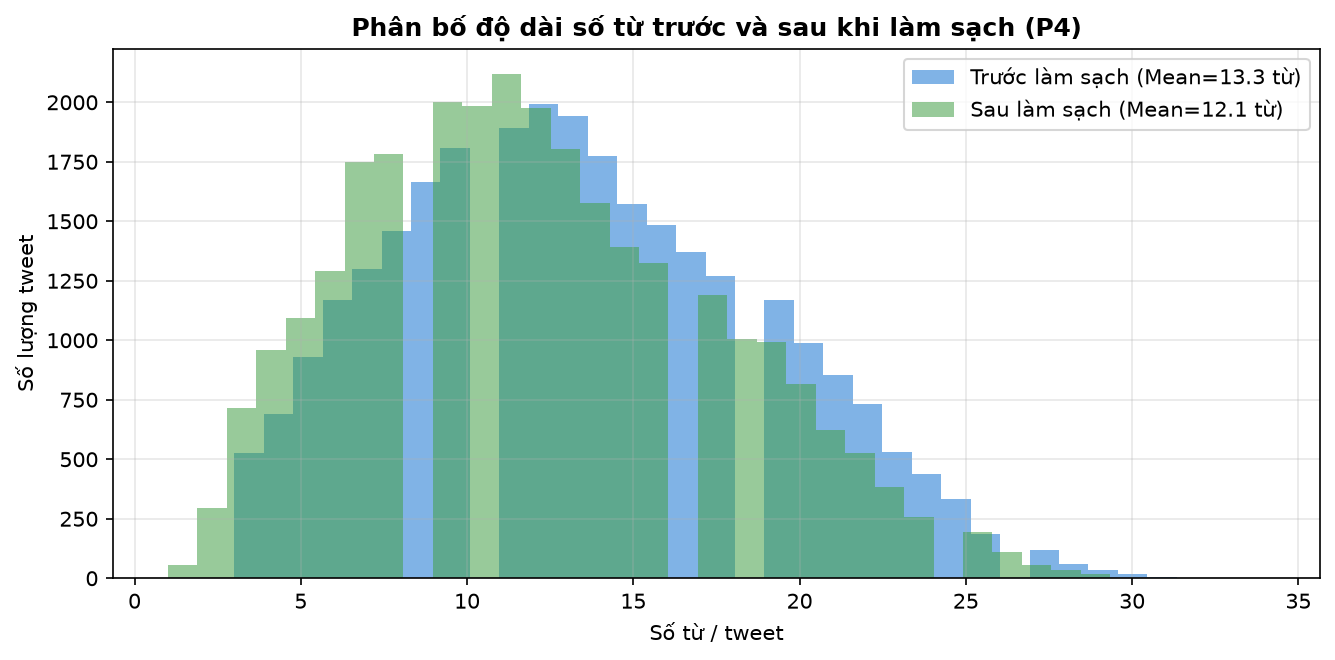

In [2]:
import json
import pandas as pd
from IPython.display import display, Image

examples_df = pd.read_csv('reports/tables/P4_clean_examples.csv')
display(examples_df)
display(Image('reports/figures/P4_length_before_after.png'))

## 2. Thống kê Khử trùng, Loại bỏ Nhãn mâu thuẫn & Chia tập Stratified 70/15/15

In [3]:
with open('reports/p4_summary.json', 'r', encoding='utf-8') as f:
    p4_data = json.load(f)

sp = p4_data['split_summary']
print('=== THỐNG KÊ LÀM SẠCH & KHỬ TRÙNG  ===')
print(f"Số dòng ban đầu (hate_train.csv)       : {sp['n_initial_raw']:,}")
print(f"Số dòng rỗng sau khi clean_text        : {sp['n_empty_dropped']:,}")
print(f"Số nhóm text_clean có nhãn mâu thuẫn   : {sp['n_conflict_groups']:,} ({sp['n_conflict_rows_dropped']} dòng bị loại)")
print(f"Số dòng trùng lặp gần-giống (Retweet)  : {sp['n_near_duplicate_rows_dropped']:,}")
print(f"Tổng số dòng bị loại bỏ                : {sp['n_total_dropped']:,}")
print(f"Số dòng sạch duy nhất còn lại          : {sp['n_final_unique_clean']:,} (Lớp 1 = {sp['final_label_1']:,}, tỉ lệ {sp['final_pos_rate_pct']:.2f}%)")

splits_table = pd.DataFrame(sp['splits']).T
print('\n=== PHÂN BỐ CÁC TẬP TRAIN / VAL / TEST (70 / 15 / 15) ===')
display(splits_table)

=== THỐNG KÊ LÀM SẠCH & KHỬ TRÙNG  ===
Số dòng ban đầu (hate_train.csv)       : 31,962
Số dòng rỗng sau khi clean_text        : 2
Số nhóm text_clean có nhãn mâu thuẫn   : 1 (2 dòng bị loại)
Số dòng trùng lặp gần-giống (Retweet)  : 3,628
Tổng số dòng bị loại bỏ                : 3,632
Số dòng sạch duy nhất còn lại          : 28,330 (Lớp 1 = 1,846, tỉ lệ 6.52%)

=== PHÂN BỐ CÁC TẬP TRAIN / VAL / TEST (70 / 15 / 15) ===


,n_rows,label_0,label_1,pos_rate_pct
train,19830.0,18538.0,1292.0,6.5154
val,4250.0,3973.0,277.0,6.5176
test,4250.0,3973.0,277.0,6.5176


## 3. So sánh 6 Chiến lược Cân bằng Dữ liệu trên 5-Fold StratifiedKFold CV 

,strategy,description,precision_mean,precision_std,recall_mean,recall_std,f1_pos_mean,f1_pos_std,pr_auc_mean,pr_auc_std,roc_auc_mean,fit_seconds
0,ros,RandomOverSampler (ROS),0.5105,0.0218,0.6935,0.0209,0.5876,0.0117,0.6337,0.0217,0.9367,2.86
1,smote,SMOTE (k=5),0.5070,0.0436,0.6803,0.0277,0.5794,0.0237,0.6269,0.0228,0.9348,3.02
2,smote_tomek,SMOTETomek,0.5070,0.0436,0.6803,0.0277,0.5794,0.0237,0.6269,0.0228,0.9348,55.20
3,class_weight,Trọng số lớp (class_weight='balanced'),0.4733,0.0162,0.7307,0.0295,0.5742,0.0169,0.6263,0.0204,0.9369,2.67
4,rus,RandomUnderSampler (RUS),0.2827,0.0119,0.8367,0.0069,0.4225,0.0131,0.5493,0.0251,0.9199,2.49
5,none,Không cân bằng (None),0.8726,0.0454,0.1385,0.0131,0.2390,0.0207,0.6200,0.0199,0.9346,2.65


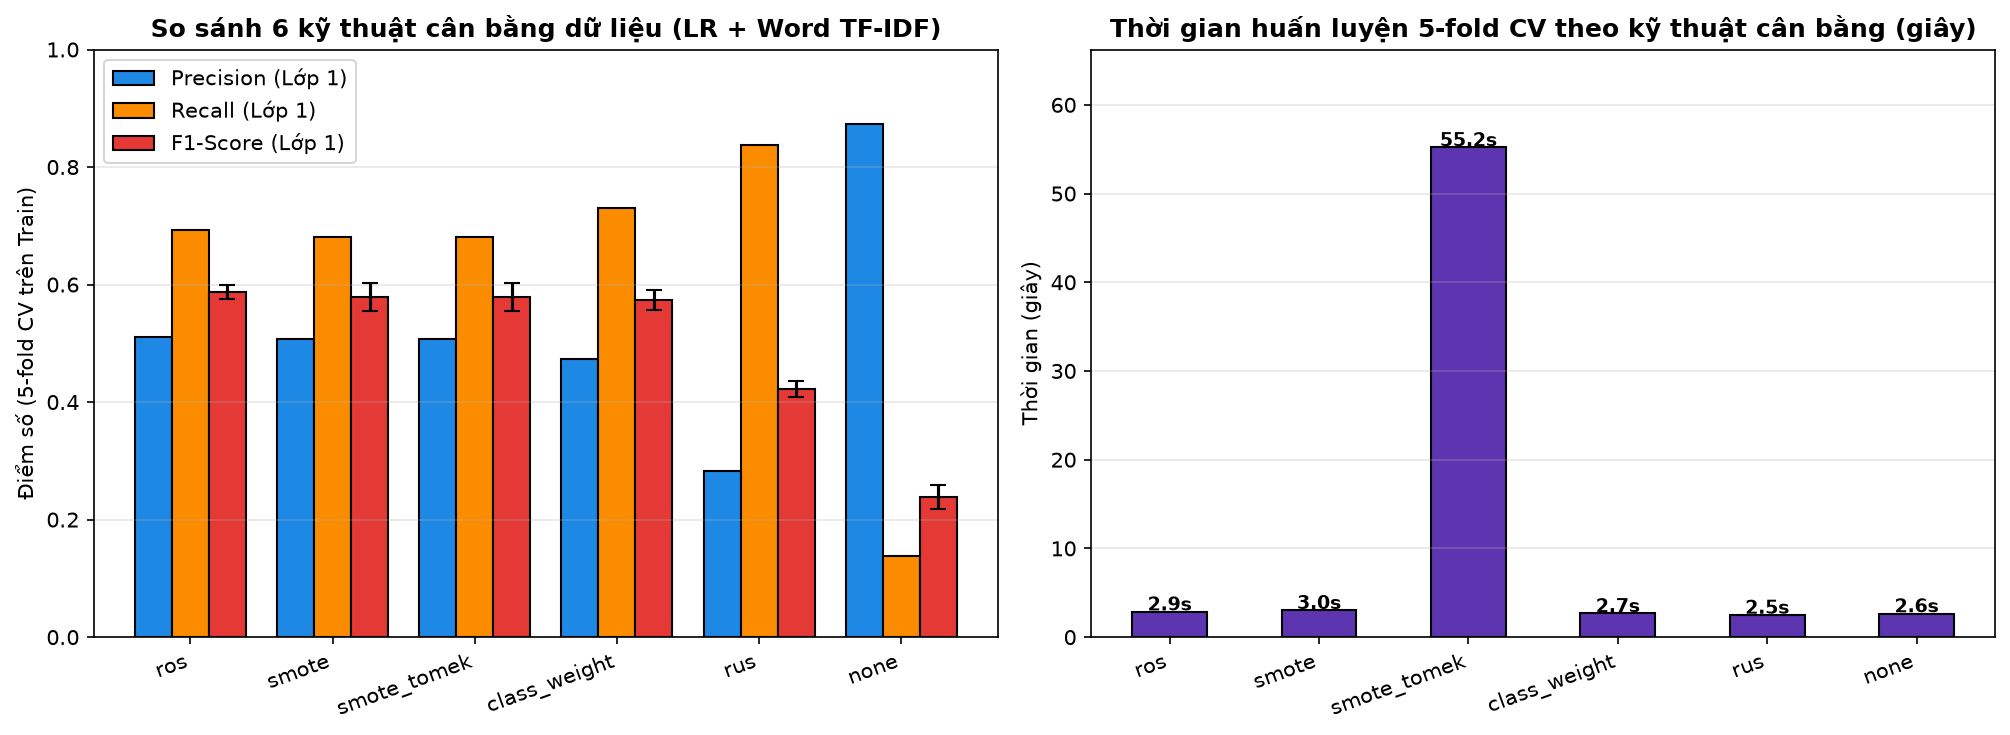

Quyết định chọn chiến lược cân bằng: Chiến lược 'ros' đạt CV F1 lớp dương cao nhất (0.5876 ± 0.0117) và PR-AUC = 0.6337 trên 5-fold StratifiedKFold tập train.


In [4]:
bal_df = pd.read_csv('reports/tables/P4_balance_comparison.csv')
display(bal_df)
display(Image('reports/figures/P4_balance_comparison.png'))
print('Quyết định chọn chiến lược cân bằng:', p4_data['balance_comparison']['chosen_reason'])

### Nhận xét 
- Quá trình khử trùng đã loại bỏ **3,628 tweet trùng/retweet** và **2 dòng mâu thuẫn nhãn**, đưa bộ dữ liệu về **28,330 mẫu duy nhất** và đảm bảo giao nhau giữa 3 tập `train`, `val`, `test` bằng $\emptyset$ (đã kiểm chứng tự động qua `tests/test_leakage.py`).
- Khi không cân bằng dữ liệu (`none`), mô hình Logistic Regression chỉ đạt Recall = **13.85%** và F1 = **0.2390** (bỏ sót hơn 86% tweet phản cảm).
- Các kỹ thuật cân bằng giúp tăng vọt F1 lên vùng **0.5742 – 0.5876**, trong đó **RandomOverSampler (`ros`)** đạt F1 trung bình 5-fold CV cao nhất (**0.5876 ± 0.0117**, PR-AUC = **0.6337**) với thời gian chạy chỉ **2.86 giây**, nên được chọn làm chiến lược cân bằng chuẩn cho bước huấn luyện mô hình.